# 06b ablations: history length and pooling

The half of step 6 that trains. Every run here is a fine-tuning run from the same `pretrain/best`, so the laptop can do it; the ablations that need a new pretraining run (tokenizer switches, CLM vs MLM, the perplexity-vs-PR-AUC scatter) are notebook 06c and wait for the T4.

| ablation | arms | runs | talk it tests |
|---|---|---|---|
| history length | H = 0, 5, 12, 32 previous transactions, last-token pooling | 4 x 3 seeds | WF: "long history is the single biggest driver" |
| pooling | last token vs mean over the sequence, at H = 12 | 1 x 3 seeds (the last-token arm is shared) | WF: last-token pooling won every time |

Fifteen runs, resumable, finished runs skipped by their json. The same split, sampling, learning rate, epochs and metrics as step 4.

**Same-machine rule.** This notebook may run on the Colab T4 (fp16) or on the laptop (Apple MPS or CPU, fp32). Training is not bit-reproducible across machines, so an ablation is only read within one machine: the H12 arm is trained here again instead of borrowed from step 4, and every json records `runtime`. Before any training on a new machine, three gates:

```
G1  every checkpoint folder is complete and self-consistent           verify_checkpoint
G2  a T4 checkpoint re-scored here reproduces its saved test scores    load + forward, no training
G3  H12 seed 0 trained here lands inside the T4 seed spread (04 json)  the first run of the list
```

In [1]:
import os, sys, glob, shutil
try:
    from google.colab import drive, userdata                      # Colab: mount Drive, pull the repo, sync new notebooks to Drive
    drive.mount("/content/drive")
    tok = userdata.get("GH_TOKEN")
    if not os.path.exists("/content/transaction-fm"):
        !git clone -q https://{tok}@github.com/lb603487485/transaction-fm.git /content/transaction-fm
    else:
        !cd /content/transaction-fm && git pull -q
    %pip install -q datasets xgboost
    %cd /content/transaction-fm
except ImportError:                                               # laptop: this notebook is the repo copy; data under $TFM_ROOT
    here = os.getcwd()
    while not os.path.isdir(os.path.join(here, "src", "tfm")):
        assert here != os.path.dirname(here), "run this notebook from inside the transaction-fm repo"
        here = os.path.dirname(here)
    %cd {here}
sys.path.insert(0, os.path.abspath("src"))
from tfm.runtime import root, describe, on_colab
ROOT = root()
os.makedirs(f"{ROOT}/notebooks", exist_ok=True)
if on_colab():
    for f in glob.glob("notebooks/*.ipynb"):                      # new notebooks from the repo appear in Drive
        dst = f"{ROOT}/notebooks/{os.path.basename(f)}"
        if not os.path.exists(dst):
            shutil.copy(f, dst); print("new notebook in Drive:", os.path.basename(f))
import tfm
print("tfm ok |", describe(), "| ROOT =", ROOT)

/Users/evolin1/Desktop/AICoding/MLProject/transaction-fm
tfm ok | {'where': 'laptop', 'gpu': None, 'device': 'cpu', 'accelerator': 'mps', 'fp16': False, 'machine': 'Darwin arm64 12 cores'} | ROOT = /Users/evolin1/Desktop/AICoding/MLProject/transaction-fm


## Stage 6b-0: data, examples, and where this is running

In [2]:
import json, time, os, numpy as np, pandas as pd
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
from pathlib import Path
from tfm.tokenizer import TransactionTokenizer
from tfm.finetune import build_examples
from tfm.metrics import evaluate_scores, mean_sd
from tfm.checkpointing import verify_checkpoint
from tfm.ablate import RUNS, run_name, run_paths, best_checkpoint, score_test, finetune_run
from tfm.runtime import accelerator

P, PRE, RES = f"{ROOT}/data/processed", f"{ROOT}/pretrain/best", f"{ROOT}/results"
os.makedirs(RES, exist_ok=True)
df = pd.read_parquet(f"{P}/transactions.parquet")
tok = TransactionTokenizer.load(f"{PRE}/tokenizer.json")
ids_all = tok.encode(df)
card, split, fraud = df["card_id"].to_numpy(), df["split"].to_numpy(), df["is_fraud"].to_numpy()
PAD, BOS, V = tok.vocab["<PAD>"], tok.vocab["<BOS>"], len(tok.vocab)
KEEP, ALERT = 0.05, 0.006
DEV = accelerator()
examples = {}                                                            # (split, H) -> (X, y, idx), filled as needed
for H in sorted({r["history"] for r in RUNS}):
    examples[("val", H)] = build_examples(ids_all, card, split, fraud, "val", H, PAD, BOS)
    examples[("test", H)] = build_examples(ids_all, card, split, fraud, "test", H, PAD, BOS)
print("accelerator:", DEV, describe())
print(pd.DataFrame([{"H": H, "sequence length": examples[("test", H)][0].shape[1], "val examples": len(examples[("val", H)][1]), "test examples": len(examples[("test", H)][1])}
                    for H in sorted({r["history"] for r in RUNS})]).to_string(index=False))

accelerator: mps {'where': 'laptop', 'gpu': None, 'device': 'cpu', 'accelerator': 'mps', 'fp16': False, 'machine': 'Darwin arm64 12 cores'}
 H  sequence length  val examples  test examples
 0                8         83971         555719
 5               43         83971         555719
12               92         83971         555719
32              232         83971         555719


## Gate G1: every checkpoint folder on this machine is complete

`verify_checkpoint` checks the four files a resumable checkpoint needs and that `global_step` inside `trainer_state.json` matches the folder name. A folder copied half-way from Drive would fail here, before anything is loaded from it.

In [3]:
rows = []
for area in ("pretrain", "finetune", "ablate"):
    for p in sorted(Path(f"{ROOT}/{area}").glob("**/checkpoint-*")):
        rows.append({"checkpoint": str(p.relative_to(ROOT)), "problems": verify_checkpoint(p) or "ok"})
g1 = pd.DataFrame(rows)
display(g1)
G1_OK = bool(len(g1)) and all(v == "ok" for v in g1["problems"])
print(f"G1: {len(g1)} checkpoint folders, {'all complete' if G1_OK else 'PROBLEMS, stop here'}")

,checkpoint,problems
0,pretrain/checkpoint-7500,ok
1,pretrain/checkpoint-7968,ok
2,finetune/pretrained_H12/seed0/checkpoint-2500,ok
3,finetune/pretrained_H12/seed0/checkpoint-3156,ok
4,finetune/pretrained_H12/seed1/checkpoint-2500,ok
5,finetune/pretrained_H12/seed1/checkpoint-3171,ok
6,finetune/pretrained_H12/seed2/checkpoint-3000,ok
7,finetune/pretrained_H12/seed2/checkpoint-3150,ok
8,finetune/scratch_H12/seed0/checkpoint-3000,ok
9,finetune/scratch_H12/seed0/checkpoint-3156,ok


G1: 14 checkpoint folders, all complete


## Gate G2: a step-4 checkpoint re-scored here matches its saved scores

Loads the checkpoint `load_best_model_at_end` restored for `pretrained_H12/seed0`, scores the test examples with plain forward passes on this machine, and compares with the `test_scores.npy` that run saved. Loading is exact (fp32 safetensors); the forward pass differs between a T4 running fp16 and a laptop running fp32 at the level of float noise. If PR-AUC agrees to 1e-3, training results from this machine can be compared with the T4's; if it does not, something is wrong with the data, the tokenizer or the examples, and nothing below should run.

In [4]:
from transformers import GPT2ForSequenceClassification
ck = best_checkpoint(f"{ROOT}/finetune/pretrained_H12/seed0")
saved = np.load(f"{ROOT}/finetune/pretrained_H12/seed0/test_scores.npy")
Xt, yt, it = examples[("test", 12)]
assert ck is not None, "no complete checkpoint for pretrained_H12/seed0 on this machine"
t0 = time.time()
model = GPT2ForSequenceClassification.from_pretrained(ck); model.config.pad_token_id = PAD
here = score_test(model, Xt, PAD, DEV)
print(f"re-scored {len(here):,} test rows on {DEV} from {Path(ck).relative_to(ROOT)} in {time.time() - t0:.0f} s")
d = np.abs(here - saved)
m_here, m_saved = evaluate_scores(yt, here, card[it], ALERT), evaluate_scores(yt, saved, card[it], ALERT)
g2 = {"checkpoint": str(Path(ck).relative_to(ROOT)), "device_here": DEV, "max_abs_diff": float(d.max()), "share_within_1e-3": float((d < 1e-3).mean()),
      "pr_auc_here": m_here["pr_auc"], "pr_auc_saved": m_saved["pr_auc"], "recall_here": m_here["recall_at_alert"], "recall_saved": m_saved["recall_at_alert"]}
print(json.dumps(g2, indent=1))
G2_OK = abs(g2["pr_auc_here"] - g2["pr_auc_saved"]) < 1e-3
print("G2:", "PASS, this machine reproduces the T4 scores" if G2_OK else "FAIL, do not train here until this is understood")
assert G1_OK and G2_OK
del model

W1102 18:38:55.264000 94493 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/77 [00:00<?, ?it/s]

re-scored 555,719 test rows on mps from finetune/pretrained_H12/seed0/checkpoint-2500 in 412 s
{
 "checkpoint": "finetune/pretrained_H12/seed0/checkpoint-2500",
 "device_here": "mps",
 "max_abs_diff": 0.0020438432693481445,
 "share_within_1e-3": 0.9999694089998722,
 "pr_auc_here": 0.9859695885201921,
 "pr_auc_saved": 0.985963696554135,
 "recall_here": 0.9883449883449883,
 "recall_saved": 0.9883449883449883
}
G2: PASS, this machine reproduces the T4 scores


## Runs, with gate G3 first

`finetune_run` is the step-4 loop as a function: train examples sampled with the run's seed, Trainer with the step-4 settings, resume from the newest complete checkpoint, verify checkpoints, score the test set, write the json. The first run in `RUNS` is H12 last-token seed 0, the same configuration step 4 trained on the T4: its test PR-AUC is printed next to the T4 mean and sd from `04_finetune.json`, and its wall time says what the remaining fourteen will cost here. The loop continues regardless; the G3 verdict is recorded in the json for the report to quote.

In [5]:
ft_path = next(p for p in (f"{RES}/04_finetune.json", "results/metrics/04_finetune.json") if os.path.exists(p))
t4 = json.load(open(ft_path))["aggregate_test"]["pretrained"]
results, g3 = [], None
for i, r in enumerate(RUNS):
    s = finetune_run(r, ids_all, card, split, fraud, PAD, BOS, V, PRE, ROOT, RES, examples, keep=KEEP, alert=ALERT)
    results.append(s)
    if i == 0:
        z = (s["test"]["pr_auc"] - t4["pr_auc"]["mean"]) / max(t4["pr_auc"]["sd"], 1e-9)
        g3 = {"local_pr_auc": s["test"]["pr_auc"], "t4_mean": t4["pr_auc"]["mean"], "t4_sd": t4["pr_auc"]["sd"], "z": float(z),
              "within_3sd": bool(abs(z) <= 3), "runtime": s["runtime"], "wall_min": s.get("wall_min")}
        print(f"\nG3: local H12 seed0 PR-AUC {s['test']['pr_auc']:.4f} vs T4 {t4['pr_auc']['mean']:.4f} +- {t4['pr_auc']['sd']:.4f}  (z = {z:+.1f}, "
              f"{'inside' if abs(z) <= 3 else 'OUTSIDE'} 3 sd)  |  this run took {s.get('wall_min')} min on {s['runtime'].get('accelerator', s['runtime']['device'])}\n")


==== 06b_H12_last_seed0 ====  67,288 train examples (7,017 fraud), sequence length 92, accelerator mps


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: /Users/evolin1/Desktop/AICoding/MLProject/transaction-fm/pretrain/best
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


resuming from: start
training: 3,156 steps total, starting at step 0, eval and save every 500 steps


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


step 50/3,156  1.6%  loss 0.597  lr 1.6e-05  elapsed 0.1 min  eta 9 min
step 100/3,156  3.2%  loss 0.039  lr 3.1e-05  elapsed 0.3 min  eta 9 min
step 150/3,156  4.8%  loss 0.042  lr 4.7e-05  elapsed 0.4 min  eta 8 min
step 200/3,156  6.3%  loss 0.035  lr 5.0e-05  elapsed 0.6 min  eta 8 min
step 250/3,156  7.9%  loss 0.027  lr 5.0e-05  elapsed 0.7 min  eta 8 min
step 300/3,156  9.5%  loss 0.023  lr 5.0e-05  elapsed 0.8 min  eta 8 min
step 350/3,156  11.1%  loss 0.023  lr 5.0e-05  elapsed 1.0 min  eta 8 min
step 400/3,156  12.7%  loss 0.028  lr 4.9e-05  elapsed 1.1 min  eta 8 min
step 450/3,156  14.3%  loss 0.029  lr 4.9e-05  elapsed 1.2 min  eta 7 min
step 500/3,156  15.8%  loss 0.011  lr 4.8e-05  elapsed 1.4 min  eta 7 min
eval @ 500  val loss 0.0042  ppl 1.00  acc: 


... (456 outputs left out)

/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


eval @ 3,150  val loss 0.0138  ppl 1.01  acc: 


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved checkpoint-3,150 to Drive
  checkpoint-3000    ok
  checkpoint-3150    ok
06b_H12_mean_seed2: best step 3000  val PR-AUC 0.8918  |  test PR-AUC 0.8941  recall@0.6% 0.905  card discovery 0.986  FP ratio 0.72  |  22.1 min


## Tables and the history curve

run,H,pooling,seed,best step,val PR-AUC,pr_auc,roc_auc,recall_at_alert,card_discovery,fp_ratio,min,where
06b_H12_last_seed0,12,last,0,3000,0.9800,0.9836,0.9997,0.9865,1.0000,0.5756,22.300000,mps
06b_H0_last_seed0,0,last,0,3000,0.7982,0.7411,0.9958,0.7683,0.9725,1.0231,2.600000,mps
06b_H0_last_seed1,0,last,1,3171,0.8042,0.7456,0.9958,0.7683,0.9817,1.0231,2.600000,mps
06b_H0_last_seed2,0,last,2,3000,0.7962,0.7347,0.9958,0.7650,0.9817,1.0317,2.600000,mps
06b_H5_last_seed0,5,last,0,2000,0.9832,0.9793,0.9997,0.9832,0.9908,0.5808,10.300000,mps
06b_H5_last_seed1,5,last,1,3000,0.9810,0.9766,0.9994,0.9832,0.9908,0.5808,10.300000,mps
06b_H5_last_seed2,5,last,2,2000,0.9798,0.9804,0.9996,0.9846,0.9954,0.5786,10.300000,mps
06b_H12_last_seed1,12,last,1,2500,0.9826,0.9829,0.9996,0.9860,1.0000,0.5764,23.500000,mps
06b_H12_last_seed2,12,last,2,3000,0.9824,0.9869,0.9996,0.9888,1.0000,0.5719,24.600000,mps
06b_H32_last_seed0,32,last,0,2000,0.9791,0.9837,0.9995,0.9869,1.0000,0.5749,88.500000,mps


history length (last-token pooling), test, mean +- sd over seeds
  H=0   pr_auc 0.7405+-0.0055  roc_auc 0.9958+-0.0000  recall_at_alert 0.7672+-0.0019  card_discovery 0.9786+-0.0053  fp_ratio 1.0259+-0.0050
  H=5   pr_auc 0.9788+-0.0019  roc_auc 0.9996+-0.0002  recall_at_alert 0.9837+-0.0008  card_discovery 0.9924+-0.0026  fp_ratio 0.5801+-0.0013
  H=12  pr_auc 0.9845+-0.0021  roc_auc 0.9996+-0.0000  recall_at_alert 0.9871+-0.0015  card_discovery 1.0000+-0.0000  fp_ratio 0.5746+-0.0024
  H=32  pr_auc 0.9843+-0.0008  roc_auc 0.9996+-0.0000  recall_at_alert 0.9871+-0.0012  card_discovery 1.0000+-0.0000  fp_ratio 0.5746+-0.0019
pooling at H=12
  last  pr_auc 0.9845+-0.0021  roc_auc 0.9996+-0.0000  recall_at_alert 0.9871+-0.0015  card_discovery 1.0000+-0.0000  fp_ratio 0.5746+-0.0024
  mean  pr_auc 0.8973+-0.0028  roc_auc 0.9953+-0.0003  recall_at_alert 0.9052+-0.0003  card_discovery 0.9862+-0.0000  fp_ratio 0.7171+-0.0005


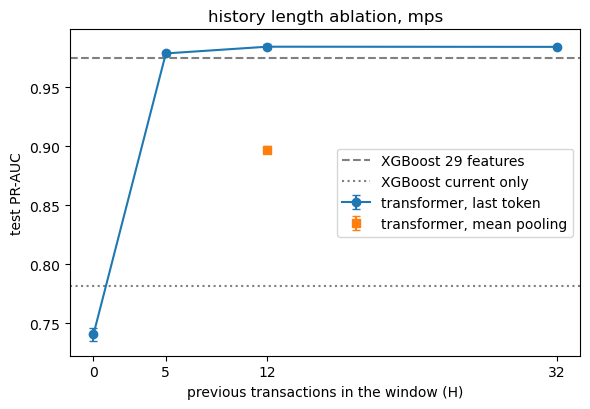

PR-AUC gain 0 -> 5: +0.2383   5 -> 12: +0.0057   12 -> 32: -0.0001


In [6]:
import matplotlib.pyplot as plt
KEYS = ["pr_auc", "roc_auc", "recall_at_alert", "card_discovery", "fp_ratio"]
tab = pd.DataFrame([{"run": s["name"], "H": s["history"], "pooling": s["pooling"], "seed": s["seed"], "best step": s["best_step"],
                     "val PR-AUC": s["val_at_best"]["pr_auc"], **{k: s["test"][k] for k in KEYS}, "min": s.get("wall_min"), "where": s["runtime"].get("accelerator", s["runtime"]["device"])} for s in results])
display(tab.style.format({c: "{:.4f}" for c in ["val PR-AUC"] + KEYS}).hide(axis="index"))

def agg(sel): return mean_sd([s["test"] for s in sel]) if sel else {}
history = {H: agg([s for s in results if s["pooling"] == "last" and s["history"] == H]) for H in sorted({s["history"] for s in results})}
pooling = {p: agg([s for s in results if s["history"] == 12 and s["pooling"] == p]) for p in ("last", "mean")}
print("history length (last-token pooling), test, mean +- sd over seeds")
for H, a in history.items():
    if a: print(f"  H={H:<3d} " + "  ".join(f"{k} {a[k]['mean']:.4f}+-{a[k]['sd']:.4f}" for k in KEYS))
print("pooling at H=12")
for p, a in pooling.items():
    if a: print(f"  {p:5s} " + "  ".join(f"{k} {a[k]['mean']:.4f}+-{a[k]['sd']:.4f}" for k in KEYS))

b5 = next((json.load(open(p)) for p in (f"{RES}/05_baseline.json", "results/metrics/05_baseline.json") if os.path.exists(p)), None)
fig, ax = plt.subplots(figsize=(6, 4.2))
Hs = [H for H, a in history.items() if a]
ax.errorbar(Hs, [history[H]["pr_auc"]["mean"] for H in Hs], yerr=[history[H]["pr_auc"]["sd"] for H in Hs], marker="o", capsize=3, label="transformer, last token")
if pooling["mean"]: ax.errorbar([12], [pooling["mean"]["pr_auc"]["mean"]], yerr=[pooling["mean"]["pr_auc"]["sd"]], marker="s", capsize=3, ls="none", label="transformer, mean pooling")
if b5:
    ax.axhline(b5["aggregate_test"]["full"]["pr_auc"]["mean"], ls="--", c="gray", label="XGBoost 29 features")
    ax.axhline(b5["aggregate_test"]["current"]["pr_auc"]["mean"], ls=":", c="gray", label="XGBoost current only")
ax.set_xlabel("previous transactions in the window (H)"); ax.set_ylabel("test PR-AUC"); ax.set_xticks(Hs); ax.legend(); ax.set_title(f"history length ablation, {DEV}")
plt.tight_layout(); fig.savefig(f"{RES}/06b_history.png", dpi=120); plt.show()
if history.get(5) and history.get(12) and history.get(0):
    print(f"PR-AUC gain 0 -> 5: {history[5]['pr_auc']['mean'] - history[0]['pr_auc']['mean']:+.4f}   5 -> 12: {history[12]['pr_auc']['mean'] - history[5]['pr_auc']['mean']:+.4f}"
          + (f"   12 -> 32: {history[32]['pr_auc']['mean'] - history[12]['pr_auc']['mean']:+.4f}" if history.get(32) else ""))

## Save 06b_ablations.json

In [7]:
out = {"runs": results, "history": history, "pooling": pooling, "gates": {"g1": {"n_checkpoints": int(len(g1)), "all_ok": G1_OK}, "g2": g2, "g3": g3},
       "t4_reference_H12": t4, "runtime": describe()}
with open(f"{RES}/06b_ablations.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved 06b_ablations.json:", list(out))

saved 06b_ablations.json: ['runs', 'history', 'pooling', 'gates', 't4_reference_H12', 'runtime']


## What to read off the numbers

- The history curve is the project's second headline after transformer-vs-XGBoost. WF says the jump is from short to long history; the guide expects the step 5 to 12 to be the biggest. Read the three gains and say which step moved most, and whether H=32 still helps or saturates (on Sparkov, cards average a transaction every few hours, so 32 rows is about a week).
- H=0 is the transformer with no history at all; compare it with the XGBoost current-only line. If they are close, the token encoding alone is not the advantage, the history is.
- Pooling: WF's claim is that last-token wins every time. A tie at three seeds is a result too: it says the last position already summarises the window on this data.
- G3 belongs in the report's methods: the configuration trained on both machines, with both numbers and the seed spread. If it fell outside 3 sd, the curve above is still internally valid (one machine), but the step-4 numbers must not be placed on the same chart.

## Push results and this notebook back to GitHub

In [8]:
import shutil, glob, os, json
os.makedirs("results/metrics", exist_ok=True); os.makedirs("results/figures", exist_ok=True)
for f in glob.glob(f"{ROOT}/results/*.json"):
    shutil.copy(f, "results/metrics/")
for f in glob.glob(f"{ROOT}/results/*.png"):
    shutil.copy(f, "results/figures/")
if on_colab():
    def same_code(a, b):   # a Drive notebook may be copied back only if its code cells equal the repo version
        cells = lambda p: ["".join(c["source"]) for c in json.load(open(p))["cells"] if c["cell_type"] == "code"]
        return cells(a) == cells(b)
    for f in glob.glob(f"{ROOT}/notebooks/*.ipynb"):   # outputs are kept so GitHub shows them
        repo = f"notebooks/{os.path.basename(f)}"
        if not os.path.exists(repo) or same_code(f, repo):
            shutil.copy(f, repo)
        else:
            print("STALE, not copied:", os.path.basename(f), "-> delete it from Drive and rerun the setup cell")
    !git config user.email "linboyy@hotmail.com" && git config user.name "Bo Lin"
    !git add results notebooks && git commit -q -m "results and notebooks from Colab" && git push -q
    !git log --oneline | head -1
else:
    print("laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal")
    !git status --short results notebooks

laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal
 M notebooks/06a_validate.ipynb
 M notebooks/06b_ablations.ipynb
?? results/figures/06a_monthly.png
?? results/figures/06b_history.png
?? results/metrics/06a_validate.json
?? results/metrics/06b_H0_last_seed0.json
?? results/metrics/06b_H0_last_seed1.json
?? results/metrics/06b_H0_last_seed2.json
?? results/metrics/06b_H12_last_seed0.json
?? results/metrics/06b_H12_last_seed1.json
?? results/metrics/06b_H12_last_seed2.json
?? results/metrics/06b_H12_mean_seed0.json
?? results/metrics/06b_H12_mean_seed1.json
?? results/metrics/06b_H12_mean_seed2.json
?? results/metrics/06b_H32_last_seed0.json
?? results/metrics/06b_H32_last_seed1.json
?? results/metrics/06b_H32_last_seed2.json
?? results/metrics/06b_H5_last_seed0.json
?? results/metrics/06b_H5_last_seed1.json
?? results/metrics/06b_H5_last_seed2.json
?? results/metrics/06b_ablations.json


In [9]:
if on_colab():
    drive.flush_and_unmount()